# 4. Logistic growth

**Model (closed form):** $P(t) = \dfrac{K}{1 + e^{-r\,(t - t_0)}}$

**Model (rate form):** $\dfrac{dP}{dt} = r\,P\left(1 - \dfrac{P}{K}\right)$

- $K$ is the **carrying capacity**: the upper limit.
- $r$ is the intrinsic growth rate (the early exponential rate).
- $t_0$ is the time of the **inflection point**, where $P = K/2$ and growth is fastest, with maximum rate $rK/4$.
- Early on ($P \ll K$) the curve looks exponential; later it saturates. Growth per unit time first accelerates, then slows.

**Why it matters.** Many sources present the logistic as the natural next step after the exponential and note that most real growth is limited (for example the Vensim dissertation from UFSJ; Castillo-Garsow, 2013; Tavoni & Oliveira, 2022). The literature also reports that students find the logistic equation hard because of its multiple representations (equation, curve, rate), so this notebook shows all three, and a **discrete recurrence** version that needs no calculus.

All data here is **simulated**; the true parameters are known.

**Contents**
1. The model, its three representations
2. A calculus-free version: the recurrence $P_{n+1} = P_n + r P_n (1 - P_n/K)\,\Delta t$
3. Simulated example A: yeast in a flask (fitting $K$, $r$, $t_0$)
4. Early data look exponential: the danger of extrapolating
5. Simulated example B: a rumour spreading in a school (stochastic simulation)
6. Simulation: how much of the curve must we observe to estimate $K$?
7. Using your own data
8. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
rng = np.random.default_rng(2026)

## 1. The model and its three representations

**Left:** the S-shaped curve for different $K$ and $r$. **Right:** the growth *rate* $dP/dt$ against $P$ is a parabola, zero at $P=0$ and $P=K$, largest at $P=K/2$.

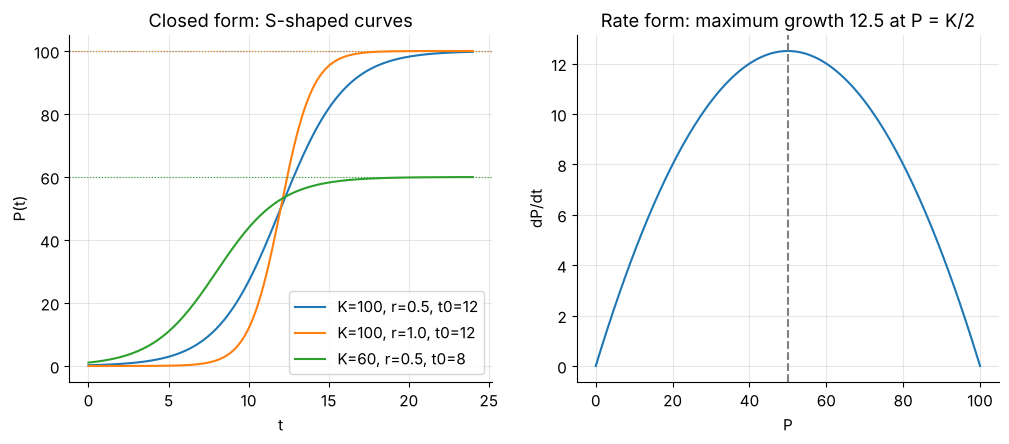

In [2]:
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

t = np.linspace(0, 24, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for K, r, t0, c in [(100, 0.5, 12, "tab:blue"), (100, 1.0, 12, "tab:orange"), (60, 0.5, 8, "tab:green")]:
    axes[0].plot(t, logistic(t, K, r, t0), color=c, label=f"K={K}, r={r}, t0={t0}")
    axes[0].axhline(K, color=c, ls=":", lw=0.8)
axes[0].set_xlabel("t")
axes[0].set_ylabel("P(t)")
axes[0].set_title("Closed form: S-shaped curves")
axes[0].legend()

K, r = 100, 0.5
P = np.linspace(0, K, 200)
axes[1].plot(P, r * P * (1 - P / K), color="tab:blue")
axes[1].axvline(K / 2, color="gray", ls="--")
axes[1].set_xlabel("P")
axes[1].set_ylabel("dP/dt")
axes[1].set_title(f"Rate form: maximum growth {r * K / 4:.1f} at P = K/2")
plt.show()

## 2. A calculus-free version: a recurrence

Step forward in small time steps $\Delta t$: $P_{n+1} = P_n + r P_n (1 - P_n/K)\,\Delta t$. This is the idea behind spreadsheet and Vensim approaches. Smaller steps approach the exact curve.

Largest gap between recurrence (Δt=0.1) and exact curve: 1.586
Inflection time t0 = ln((K-P0)/P0)/r = 7.78


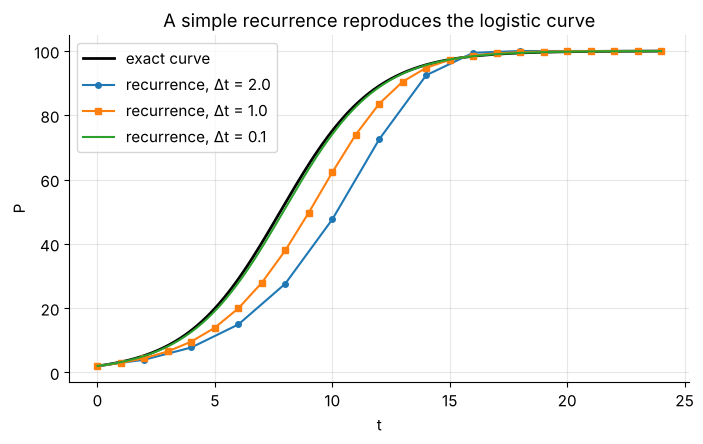

In [3]:
K, r, P0, t_end = 100.0, 0.5, 2.0, 24.0
t0_exact = np.log((K - P0) / P0) / r          # so that P(0) = P0 in the closed form

def recurrence(dt):
    steps = int(round(t_end / dt))
    times = np.arange(steps + 1) * dt
    P = np.empty(steps + 1)
    P[0] = P0
    for n in range(steps):
        P[n + 1] = P[n] + r * P[n] * (1 - P[n] / K) * dt
    return times, P

t_fine = np.linspace(0, t_end, 400)
fig, ax = plt.subplots()
ax.plot(t_fine, logistic(t_fine, K, r, t0_exact), "k", lw=2, label="exact curve")
for dt, style in [(2.0, "o-"), (1.0, "s-"), (0.1, "-")]:
    times, P = recurrence(dt)
    ax.plot(times, P, style, ms=4, label=f"recurrence, Δt = {dt}")
ax.set_xlabel("t")
ax.set_ylabel("P")
ax.set_title("A simple recurrence reproduces the logistic curve")
ax.legend()
plt.show()

times, P = recurrence(0.1)
print(f"Largest gap between recurrence (Δt=0.1) and exact curve: {np.max(np.abs(P - logistic(times, K, r, t0_exact))):.3f}")
print(f"Inflection time t0 = ln((K-P0)/P0)/r = {t0_exact:.2f}")

## 3. Simulated example A: yeast in a flask

A yeast culture in a closed flask can only grow until nutrients run out. True values: $K = 1000$ (arbitrary density units), $r = 0.5$ per hour, inflection at $t_0 = 12$ h. We measure every hour for 24 hours with multiplicative noise (about 6%), then fit $K$, $r$ and $t_0$ by nonlinear least squares.

In [4]:
true_K, true_r, true_t0 = 1000.0, 0.5, 12.0
hours = np.arange(0, 25)
density = logistic(hours, true_K, true_r, true_t0) * np.exp(rng.normal(0, 0.06, hours.size))

popt, pcov = curve_fit(logistic, hours, density, p0=[density.max() * 1.2, 0.3, 10.0], maxfev=10000)
K_hat, r_hat, t0_hat = popt
se = np.sqrt(np.diag(pcov))

print(f"K  = {K_hat:7.1f} ± {se[0]:.1f}   (true {true_K})")
print(f"r  = {r_hat:7.3f} ± {se[1]:.3f}   (true {true_r})")
print(f"t0 = {t0_hat:7.2f} ± {se[2]:.2f}   (true {true_t0})")
print(f"Maximum growth rate rK/4 = {r_hat * K_hat / 4:.1f} per hour (true {true_r * true_K / 4:.1f})")

K  =   997.6 ± 10.3   (true 1000.0)
r  =   0.484 ± 0.020   (true 0.5)
t0 =   12.00 ± 0.10   (true 12.0)
Maximum growth rate rK/4 = 120.7 per hour (true 125.0)


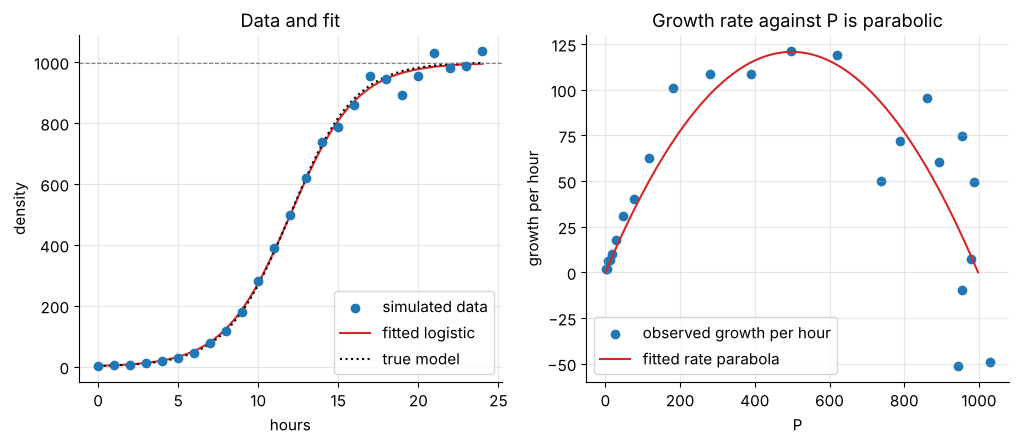

In [5]:
t_fine = np.linspace(0, 24, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(hours, density, color="tab:blue", label="simulated data", zorder=3)
axes[0].plot(t_fine, logistic(t_fine, *popt), color="tab:red", label="fitted logistic")
axes[0].plot(t_fine, logistic(t_fine, true_K, true_r, true_t0), "k:", label="true model")
axes[0].axhline(K_hat, color="gray", ls="--", lw=0.8)
axes[0].set_xlabel("hours")
axes[0].set_ylabel("density")
axes[0].set_title("Data and fit")
axes[0].legend()

# growth per hour estimated from the data: ΔP / Δt at each step
growth = np.diff(density)
axes[1].scatter(density[:-1], growth, color="tab:blue", label="observed growth per hour")
P_line = np.linspace(0, K_hat, 200)
axes[1].plot(P_line, r_hat * P_line * (1 - P_line / K_hat), color="tab:red", label="fitted rate parabola")
axes[1].set_xlabel("P")
axes[1].set_ylabel("growth per hour")
axes[1].set_title("Growth rate against P is parabolic")
axes[1].legend()
plt.show()

## 4. Early data look exponential: the danger of extrapolating

Suppose we only observe the first 8 hours, when growth looks exponential, and fit an **exponential** model. The prediction goes badly wrong once the culture approaches its limit. This is the point where students need to ask "what stops the growth?"

Early exponential rate r = 0.490 (true r of the logistic: 0.5)
Exponential extrapolation at 24 h :       316623
Observed density at 24 h          :         1037
True carrying capacity K          :         1000


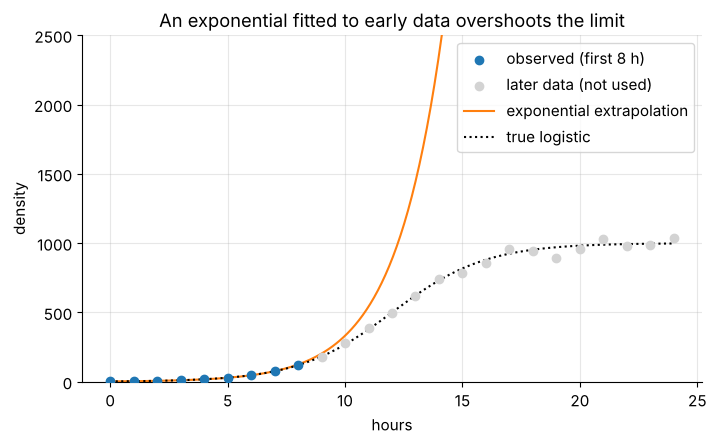

In [6]:
early = hours <= 8
lin_early = stats.linregress(hours[early], np.log(density[early]))
r_early = lin_early.slope
n0_early = np.exp(lin_early.intercept)

pred_exp_24 = n0_early * np.exp(r_early * 24)
print(f"Early exponential rate r = {r_early:.3f} (true r of the logistic: {true_r})")
print(f"Exponential extrapolation at 24 h : {pred_exp_24:12.0f}")
print(f"Observed density at 24 h          : {density[-1]:12.0f}")
print(f"True carrying capacity K          : {true_K:12.0f}")

fig, ax = plt.subplots()
ax.scatter(hours[early], density[early], color="tab:blue", label="observed (first 8 h)", zorder=3)
ax.scatter(hours[~early], density[~early], color="lightgray", label="later data (not used)", zorder=3)
ax.plot(t_fine, n0_early * np.exp(r_early * t_fine), color="tab:orange", label="exponential extrapolation")
ax.plot(t_fine, logistic(t_fine, true_K, true_r, true_t0), "k:", label="true logistic")
ax.set_ylim(0, 2500)
ax.set_xlabel("hours")
ax.set_ylabel("density")
ax.set_title("An exponential fitted to early data overshoots the limit")
ax.legend()
plt.show()

## 5. Simulated example B: a rumour spreading in a school

A **stochastic simulation**: a school has 600 students and 3 know a rumour at day 0. Each day, every student who knows the rumour tells 2 randomly chosen students. We run 20 independent simulations, plot them together, and fit a logistic curve to each. Unlike the yeast example, randomness is built into the process, not only into the measurement.

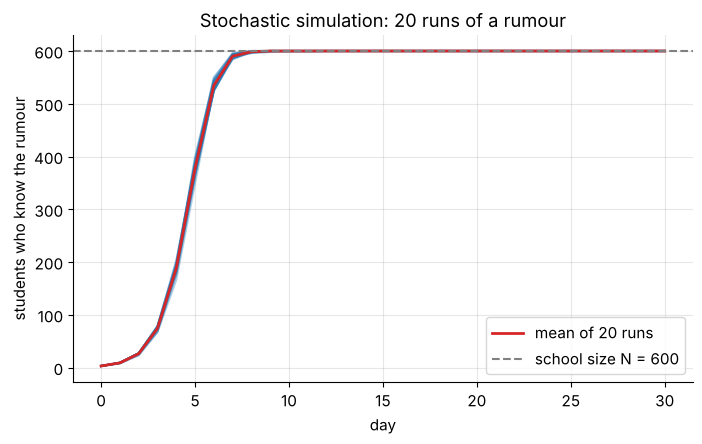

In [7]:
N, contacts_per_day, n_days, n_runs = 600, 2, 30, 20

def simulate_rumour():
    informed = np.zeros(N, dtype=bool)
    informed[rng.choice(N, size=3, replace=False)] = True
    counts = [informed.sum()]
    for _ in range(n_days):
        k = informed.sum()
        targets = rng.integers(0, N, size=contacts_per_day * k)
        informed[targets] = True
        counts.append(informed.sum())
    return np.array(counts)

days = np.arange(n_days + 1)
runs = np.array([simulate_rumour() for _ in range(n_runs)])

fig, ax = plt.subplots()
for run in runs:
    ax.plot(days, run, color="tab:blue", alpha=0.35)
ax.plot(days, runs.mean(axis=0), color="tab:red", lw=2, label="mean of 20 runs")
ax.axhline(N, color="gray", ls="--", label="school size N = 600")
ax.set_xlabel("day")
ax.set_ylabel("students who know the rumour")
ax.set_title("Stochastic simulation: 20 runs of a rumour")
ax.legend()
plt.show()

In [8]:
fits = []
for run in runs:
    try:
        p, _ = curve_fit(logistic, days, run, p0=[N, 1.0, 5.0], maxfev=10000)
        fits.append(p)
    except RuntimeError:
        pass
fits = np.array(fits)

print(f"Successful fits: {len(fits)} of {n_runs}")
print(f"K  : mean {fits[:, 0].mean():6.1f}, sd {fits[:, 0].std(ddof=1):5.1f}   (school size {N})")
print(f"r  : mean {fits[:, 1].mean():6.3f}, sd {fits[:, 1].std(ddof=1):5.3f}")
print(f"t0 : mean {fits[:, 2].mean():6.2f}, sd {fits[:, 2].std(ddof=1):5.2f}  days")

# Early phase only (fewer than 10% of the school knows): regress ln(count) on day
early_r = []
for run in runs:
    m = run <= 0.1 * N
    early_r.append(stats.linregress(days[m], np.log(run[m])).slope)
print()
print(f"Early exponential rate (while < 10% know): r ≈ {np.mean(early_r):.3f}")
print(f"If every contact reached someone new, the factor would be 1 + {contacts_per_day} = {1 + contacts_per_day} per day, i.e. r = ln 3 = {np.log(3):.3f}")
print(f"Logistic fitted to the whole curve gives a larger r ≈ {fits[:, 1].mean():.3f}")

Successful fits: 20 of 20
K  : mean  600.9, sd   0.1   (school size 600)
r  : mean  1.350, sd 0.033
t0 : mean   4.57, sd  0.06  days

Early exponential rate (while < 10% know): r ≈ 1.085
If every contact reached someone new, the factor would be 1 + 2 = 3 per day, i.e. r = ln 3 = 1.099
Logistic fitted to the whole curve gives a larger r ≈ 1.350


Early on, each informed student adds about 2 new ones per day, so the numbers grow by a factor close to 3 per day. The logistic curve fitted to the **whole** run gives a noticeably larger $r$. This is likely because this day-by-day random process saturates more sharply than the smooth logistic model assumes. Fitted parameters depend on which part of the data is used, and a model is always an approximation of the process behind the data.

## 6. Simulation: how much of the curve must we observe to estimate $K$?

We repeat the yeast experiment 300 times for four observation windows. The carrying capacity $K$ is estimated much better once the data reach and pass the inflection point at $t_0 = 12$ h.

observe up to  8 h: median K =   1025.5, IQR =    406.3 to 100000.0, failed fits = 0
observe up to 12 h: median K =   1024.4, IQR =    804.8 to   1361.3, failed fits = 0
observe up to 16 h: median K =    993.1, IQR =    940.6 to   1054.9, failed fits = 0
observe up to 24 h: median K =   1002.8, IQR =    985.0 to   1018.4, failed fits = 0


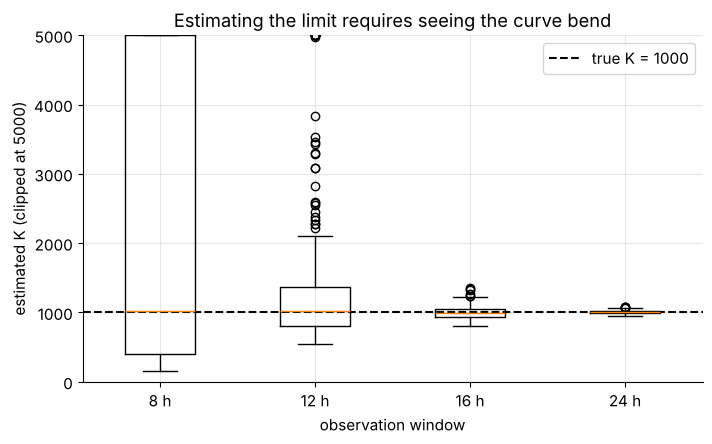

In [9]:
def estimate_K(t_max, n_tries=300):
    t_obs = np.arange(0, t_max + 1)
    estimates, failures = [], 0
    for _ in range(n_tries):
        y = logistic(t_obs, true_K, true_r, true_t0) * np.exp(rng.normal(0, 0.06, t_obs.size))
        try:
            p, _ = curve_fit(
                logistic, t_obs, y, p0=[max(y.max() * 1.5, 50), 0.3, 10.0],
                bounds=([1, 0.01, -20], [1e5, 5, 60]), maxfev=10000,
            )
            estimates.append(p[0])
        except RuntimeError:
            failures += 1
    return np.array(estimates), failures

windows = [8, 12, 16, 24]
est_K = {}
for w in windows:
    e, fails = estimate_K(w)
    est_K[w] = e
    print(f"observe up to {w:>2} h: median K = {np.median(e):8.1f}, "
          f"IQR = {np.percentile(e, 25):8.1f} to {np.percentile(e, 75):8.1f}, failed fits = {fails}")

fig, ax = plt.subplots()
ax.boxplot([np.clip(est_K[w], 0, 5000) for w in windows], tick_labels=[f"{w} h" for w in windows])
ax.axhline(true_K, color="k", ls="--", label="true K = 1000")
ax.set_ylim(0, 5000)
ax.set_xlabel("observation window")
ax.set_ylabel("estimated K (clipped at 5000)")
ax.set_title("Estimating the limit requires seeing the curve bend")
ax.legend()
plt.show()

A value of 100000 in the interquartile range is the upper bound we allowed the fit to use: with data that stop before the curve bends, the fit cannot find a limit at all.

## 7. Using your own data

In [10]:
# import pandas as pd
# df = pd.read_csv("my_data.csv")                       # columns: t, y
# p0 = [df["y"].max() * 1.2, 0.3, df["t"].median()]     # starting guesses for K, r, t0
# popt, pcov = curve_fit(logistic, df["t"], df["y"], p0=p0, maxfev=10000)
# print("K, r, t0 =", popt)

## 8. Exercises

1. In section 1 change $r$ to 0.2 and 2.0. How does the steepness at the inflection point change? Does the carrying capacity change?
2. In section 2 try `dt = 4` and then `dt = 5`. The recurrence overshoots the carrying capacity and wobbles around it. Why does a large step make this happen? (Hint: look at the factor $1 + r\,\Delta t\,(1 - P/K)$.)
3. In section 5 let each student tell 1 person per day instead of 2. How do $r$ and $t_0$ change?
4. In section 6 add the window 10 h. Is $K$ still well estimated? Where does the estimate become unreliable?
5. Show algebraically that at $P = K/2$ the rate $dP/dt$ equals $rK/4$.